# Speaker-leakage inference on the trained SparseCodec model

This notebook answers: **how much speaker information is still in the content code `h_cnt`, compared to the codec features it was derived from?**

1. **Extract the DAC quantized representations** (RVQ tokens and the dequantized `z_q`) from the pretrained 16 kHz DAC.
2. **Extract `h_cnt` and `h_spk`** from the trained disentangler (the checkpoint written by the recipe).
3. **Plot `h_cnt` / `h_spk` with speaker labels** (utterance level and frame level) and look for speaker clusters.
4. **Probe with classifiers** (speaker ID, gender, speaker verification EER) on DAC tokens, `h_cnt` and `h_spk`, and report how much speaker information was removed.

Notes
* The evaluation speakers (dev-clean by default) were **not seen in training** (train-clean-100), so the probes measure generalizing speaker information, not memorization.
* The "DAC tokens" baseline is the codec the model started from: a standard pretrained RVQ DAC (`quantizer_type="rvq"`). The recipe's own `codec` only uses the (frozen) encoder, and the notebook checks that the two encoders are identical.
* Everything expensive is cached in `CACHE_PATH`, so re-running the plotting and probing cells is fast.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from hyperpyyaml import load_hyperpyyaml
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, silhouette_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from tqdm.auto import tqdm

import speechbrain as sb
from speechbrain.lobes.models.discrete.dac import DAC

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='n_jobs value')   # umap, harmless when a seed is set

# ------------------------------- settings -------------------------------
MODEL_DIR = Path('/storage/anakuzne/debug_claude')   # contains hyperparams.yaml and save/
EVAL_CSV = MODEL_DIR / 'dev-clean.csv'               # speakers not seen in training
N_SPEAKERS = 40
UTTS_PER_SPEAKER = 20
MIN_DUR, MAX_DUR = 2.0, 15.0     # seconds, utterance selection
MAX_SECONDS = 10.0               # crop longer utterances to this length
FRAMES_PER_UTT = 20              # frames kept per utterance for the frame-level plots/probes
N_FOLDS = 5
SEED = 0
USE_CACHE = True
CACHE_PATH = MODEL_DIR / 'leakage_probe_cache.pt'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAMPLE_RATE = 16000

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
print('device:', DEVICE)

device: cuda


/home/anastasia/envs/sb/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Load the models

* **Trained model**: weights from the recipe checkpoint (`min_key="WER"`, averaged over `avg_checkpoints` exactly like `on_evaluate_start`).
* **Standard DAC (RVQ)**: pretrained 16 kHz / 8 kbps codec that produces the real DAC tokens.

In [2]:
with open(MODEL_DIR / 'hyperparams.yaml', encoding='utf-8') as f:
    hparams = load_hyperpyyaml(f)

checkpointer = sb.utils.checkpoints.Checkpointer(
    checkpoints_dir=MODEL_DIR / 'save', recoverables={'model': hparams['model']}
)
ckpts = checkpointer.find_checkpoints(min_key='WER', max_num_checkpoints=hparams['avg_checkpoints'])
assert ckpts, 'no checkpoint found in %s' % (MODEL_DIR / 'save')
for ckpt in ckpts:
    print('checkpoint:', ckpt.path.name, ckpt.meta)
state = sb.utils.checkpoints.average_checkpoints(ckpts, recoverable_name='model')
hparams['model'].load_state_dict(state, strict=True)

model = hparams['model'].to(DEVICE).eval()
codec_trained, disentangle = model[0], model[1]   # layout of the recipe's ModuleList

dac_rvq = DAC(
    model_type=hparams['model_type'], model_bitrate=hparams['model_bitrate'],
    load_pretrained=True, tag='latest', quantizer_type='rvq',
).to(DEVICE).eval()

# The recipe freezes the pretrained encoder, so both encoders must be identical.
encoder_diff = max(
    (a - b).abs().max().item()
    for a, b in zip(codec_trained.encoder.parameters(), dac_rvq.encoder.parameters())
)
print('max |encoder weight difference| (recipe codec vs standard DAC): %.2e' % encoder_diff)

N_LAYERS = hparams['num_sparse_layers']
K_CNT = disentangle.mid                    # content atoms per layer
K_SPK = disentangle.spk_dim                # speaker atoms per layer
N_CODEBOOKS = dac_rvq.quantizer.n_codebooks
CODEBOOK_SIZE = dac_rvq.quantizer.codebook_size
print('sparse layers: %d | content atoms/layer: %d | speaker atoms/layer: %d' % (N_LAYERS, K_CNT, K_SPK))
print('DAC: %d codebooks x %d entries, latent dim %d' % (N_CODEBOOKS, CODEBOOK_SIZE, dac_rvq.latent_dim))

checkpoint: CKPT+2026-11-03+10-26-27+00 {'WER': 0.0, 'end-of-epoch': True, 'epoch': None, 'unixtime': 1793719587.3556216}
max |encoder weight difference| (recipe codec vs standard DAC): 1.19e-07
sparse layers: 4 | content atoms/layer: 32 | speaker atoms/layer: 32
DAC: 12 codebooks x 1024 entries, latent dim 1024


## 2. Choose the evaluation utterances

`N_SPEAKERS` speakers with `UTTS_PER_SPEAKER` utterances each, sampled with a fixed seed. Gender comes from LibriSpeech `SPEAKERS.TXT`.

In [3]:
def read_speaker_sex(data_root):
    """{speaker id: 'M' | 'F'} from LibriSpeech SPEAKERS.TXT."""
    sex = {}
    with open(Path(data_root) / 'SPEAKERS.TXT') as f:
        for line in f:
            if line.startswith(';') or '|' not in line:
                continue
            fields = [x.strip() for x in line.split('|')]
            sex[fields[0]] = fields[1]
    return sex


table = pd.read_csv(EVAL_CSV)
table['spk'] = table['spk_id'].str.split('-').str[0]          # speaker label, as in the recipe
table['wav'] = table['wav'].str.replace('$data_root', hparams['data_folder'].rstrip('/'), regex=False)
table = table[(table['duration'] >= MIN_DUR) & (table['duration'] <= MAX_DUR)]

counts = table['spk'].value_counts()
eligible = sorted(counts[counts >= UTTS_PER_SPEAKER].index)
speakers = sorted(rng.choice(eligible, size=min(N_SPEAKERS, len(eligible)), replace=False))
parts = [
    table[table['spk'] == spk].sample(UTTS_PER_SPEAKER, random_state=SEED)
    for spk in speakers
]
utts = pd.concat(parts).reset_index(drop=True)
utts['sex'] = utts['spk'].map(read_speaker_sex(hparams['data_folder'])).fillna('U')
utts['spk_idx'] = utts['spk'].map({s: i for i, s in enumerate(speakers)})

print('%d speakers (%s), %d utterances, %.1f h of audio' % (
    len(speakers), ', '.join('%s: %d' % kv for kv in utts.drop_duplicates('spk')['sex'].value_counts().items()),
    len(utts), utts['duration'].clip(upper=MAX_SECONDS).sum() / 3600))
utts[['ID', 'spk', 'sex', 'duration']].head()

40 speakers (M: 20, F: 20), 800 utterances, 1.4 h of audio


,ID,spk,sex,duration
0,1272-141231-0003,1272,M,5.420
1,1272-135031-0023,1272,M,7.520
2,1272-135031-0021,1272,M,2.595
3,1272-141231-0020,1272,M,4.320
4,1272-141231-0015,1272,M,5.680


## 3. Extract DAC tokens, `h_cnt` and `h_spk`

For every utterance:

| quantity | source | shape |
|---|---|---|
| DAC tokens `codes` | `dac_rvq.quantizer(encoder(wav))` | `[n_codebooks, T]` integers |
| DAC quantized embedding `z_q` | same call, sum of the dequantized codebook vectors | `[1024, T]` |
| `h_cnt` | `disentangle(encoder(wav))`, all layers concatenated | `[layers x K_cnt, T]` (time-varying) |
| `h_spk` | same | `[layers x K_spk]` (one vector per utterance) |

Utterance-level features are pooled over time: token histogram (DAC), mean/std of `z_q`, and mean/std/mean-abs of `h_cnt` (the same
statistics the recipe uses for `leak_EER`). A few random frames per utterance are kept for the frame-level analyses.

In [4]:
@torch.no_grad()
def extract_utterance(wav_path):
    """All representations for one utterance (batch size 1, so no padding mask is needed)."""
    wav = sb.dataio.dataio.read_audio(wav_path)[: int(MAX_SECONDS * SAMPLE_RATE)]
    wav = wav.to(DEVICE)[None, None]                                  # [1, 1, samples]

    # 1. DAC: encoder -> residual vector quantizer -> tokens and dequantized embedding
    z_dac = dac_rvq.encoder(wav)                                      # [1, 1024, T]
    z_q, codes, _, _, _ = dac_rvq.quantizer(z_dac)                    # [1, 1024, T], [1, n_cb, T]

    # 2. Trained disentangler (same encoder weights as the DAC above)
    z = codec_trained.encoder(wav)
    _, _, _, h_cnt, h_spk, _, _ = disentangle(z, stage=sb.Stage.TEST, wav_lens=None)
    return (
        codes[0].cpu().numpy().astype(np.int16),                       # [n_cb, T]
        z_q[0].cpu().numpy(),                                          # [1024, T]
        h_cnt[0].cpu().numpy(),                                        # [L*K_cnt, T]
        h_spk[0, :, 0].cpu().numpy(),                                  # [L*K_spk]
    )


def pool_stats(x):
    """[D, T] -> [3 D]: mean, std and mean-absolute value over time."""
    return np.concatenate([x.mean(1), x.std(1), np.abs(x).mean(1)])


def token_histogram(codes):
    """[n_cb, T] -> [n_cb * codebook_size] normalized token counts."""
    return np.concatenate([np.bincount(c, minlength=CODEBOOK_SIZE) for c in codes.astype(np.int64)]) / codes.shape[1]


cache_key = json.dumps(dict(
    csv=str(EVAL_CSV), ids=list(utts['ID']), max_seconds=MAX_SECONDS, frames=FRAMES_PER_UTT, seed=SEED,
    ckpt=[str(c.path) for c in ckpts], ckpt_time=[c.meta.get('unixtime') for c in ckpts],
    n_layers=N_LAYERS, n_codebooks=N_CODEBOOKS,
))

data = None
if USE_CACHE and CACHE_PATH.exists():
    cached = torch.load(CACHE_PATH, weights_only=False)
    if cached.get('key') == cache_key:
        data = cached
        print('loaded cached features from', CACHE_PATH)

if data is None:
    feats = {k: [] for k in ('dac_tokens', 'dac_zq', 'h_cnt', 'h_spk')}
    frames = {k: [] for k in ('h_cnt', 'zq', 'utt')}
    examples, density, n_frames = {}, [], []
    frame_rng = np.random.default_rng(SEED)
    for i, row in enumerate(tqdm(utts.itertuples(), total=len(utts), desc='extracting')):
        codes, z_q, h_cnt, h_spk = extract_utterance(row.wav)
        feats['dac_tokens'].append(token_histogram(codes))
        feats['dac_zq'].append(pool_stats(z_q)[: 2 * z_q.shape[0]])   # mean and std only
        feats['h_cnt'].append(pool_stats(h_cnt))
        feats['h_spk'].append(h_spk)
        idx = frame_rng.choice(h_cnt.shape[1], size=min(FRAMES_PER_UTT, h_cnt.shape[1]), replace=False)
        frames['h_cnt'].append(h_cnt[:, idx].T)
        frames['zq'].append(z_q[:, idx].T)
        frames['utt'].append(np.full(len(idx), i))
        density.append((np.abs(h_cnt) > 1e-4).mean())
        n_frames.append(h_cnt.shape[1])
        if row.spk not in examples and len(examples) < 3:          # full codes of 3 speakers for the heatmaps
            examples[row.spk] = dict(utt=i, codes=codes, h_cnt=h_cnt, h_spk=h_spk)
    data = dict(
        key=cache_key,
        feats={k: np.stack(v).astype(np.float32) for k, v in feats.items()},
        frames={k: np.concatenate(v).astype(np.float32) if k != 'utt' else np.concatenate(v) for k, v in frames.items()},
        examples=examples, density=np.array(density), n_frames=np.array(n_frames),
    )
    if USE_CACHE:
        torch.save(data, CACHE_PATH)
        print('cached features to', CACHE_PATH)

feats, frames, examples = data['feats'], data['frames'], data['examples']
frame_spk = utts['spk_idx'].values[frames['utt']]
print({k: v.shape for k, v in feats.items()})
print('frame-level:', {k: v.shape for k, v in frames.items()})

loaded cached features from /storage/anakuzne/debug_claude/leakage_probe_cache.pt
{'dac_tokens': (800, 12288), 'dac_zq': (800, 2048), 'h_cnt': (800, 384), 'h_spk': (800, 128)}
frame-level: {'h_cnt': (16000, 128), 'zq': (16000, 1024), 'utt': (16000,)}


### What was extracted

One example utterance: its DAC tokens (one row per codebook, one column per frame), and a summary of the sparse codes.

In [5]:
first = next(iter(examples.values()))
print('example utterance:', utts.loc[first['utt'], 'ID'], '| speaker', utts.loc[first['utt'], 'spk'])
print('DAC tokens  [n_codebooks, T]:', first['codes'].shape, '- first 12 frames of the first 4 codebooks:')
print(first['codes'][:4, :12])
print('h_cnt       [layers x K_cnt, T]:', first['h_cnt'].shape, '| active entries: %.1f%% (all utterances: %.1f%%)' % (
    100 * (np.abs(first['h_cnt']) > 1e-4).mean(), 100 * data['density'].mean()))
print('h_spk       [layers x K_spk]:', first['h_spk'].shape, '| active entries: %.1f%%' % (100 * (np.abs(first['h_spk']) > 1e-4).mean()))
used = len(np.unique(np.concatenate([e['codes'] for e in examples.values()], axis=1)))
print('distinct DAC token ids seen in these examples:', used)

example utterance: 1272-141231-0003 | speaker 1272
DAC tokens  [n_codebooks, T]: (12, 271) - first 12 frames of the first 4 codebooks:
[[ 734    1  301  222   25  222  707    1  320  256  330  958]
 [ 554  425  619  453  553  323  458  278  425  390  178  341]
 [ 463  840  702  667  312  677   12   92  631  454  373  464]
 [ 256  253  488  888  855  202  347  654  648  991 1007  746]]
h_cnt       [layers x K_cnt, T]: (128, 271) | active entries: 6.0% (all utterances: 6.1%)
h_spk       [layers x K_spk]: (128,) | active entries: 68.8%
distinct DAC token ids seen in these examples: 1024


## 4. Visual check: do speakers cluster in `h_cnt`?

2-D UMAP (cosine) of standardized, PCA-reduced features. **Colour = speaker, marker = gender** (circle = male, triangle = female).
If `h_cnt` is free of speaker information its panel should show **no per-speaker islands**, unlike `h_spk`, which is the reference for what a speaker code looks like. Each title also reports the **cosine silhouette score by speaker** (about 0 = no speaker structure, 1 = perfect clusters).

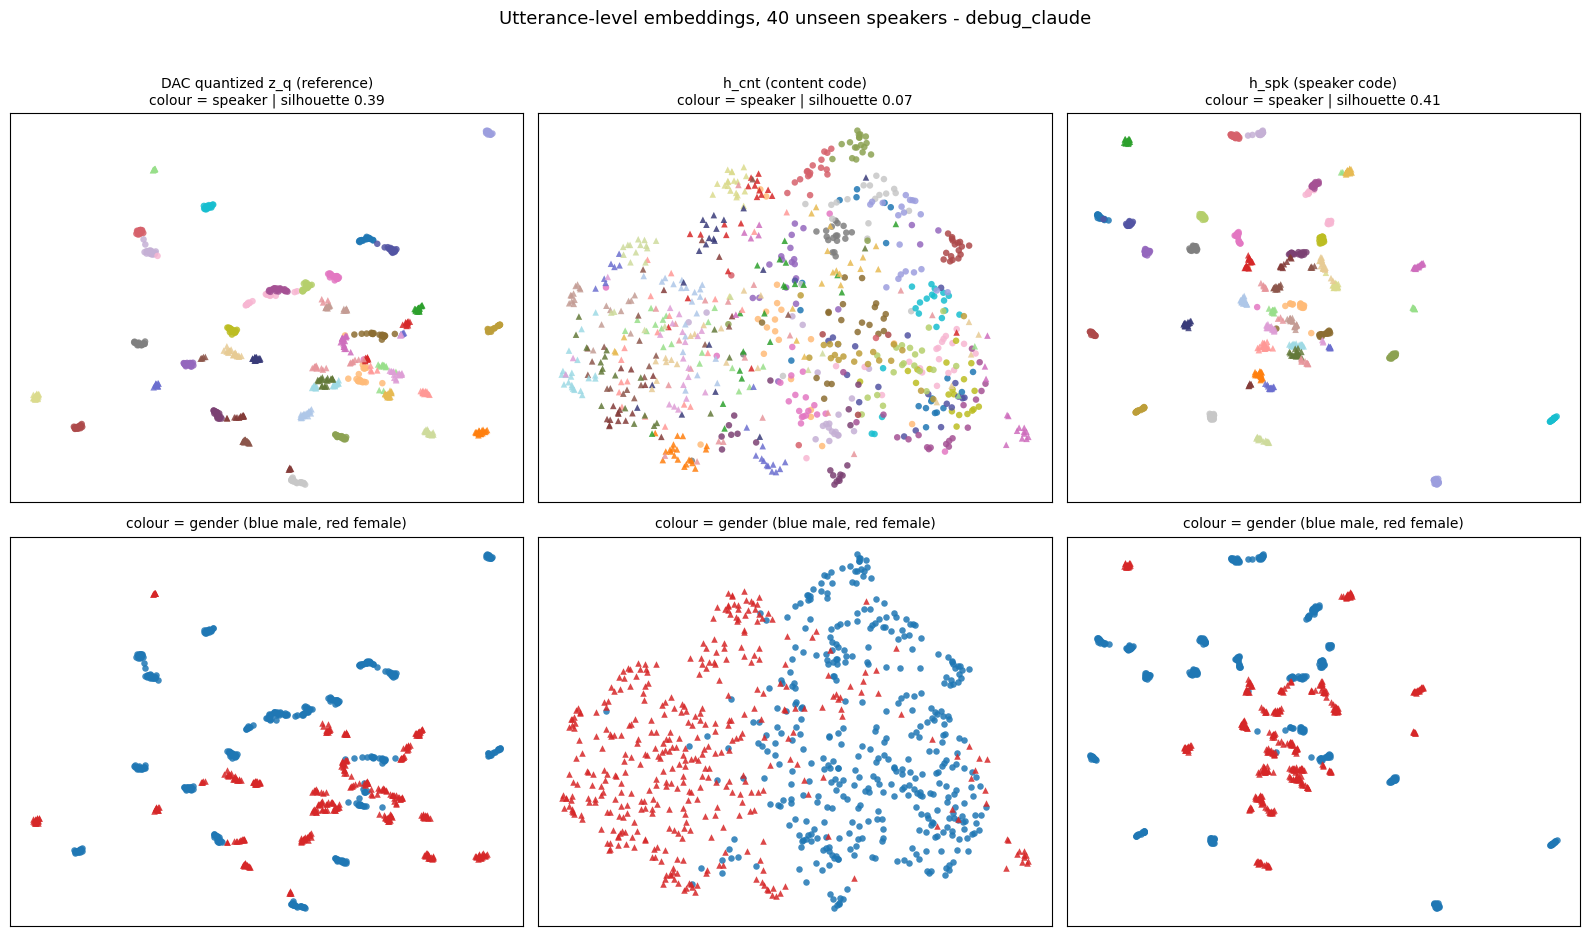

In [6]:
SPEAKER_COLORS = np.vstack([plt.get_cmap('tab20')(np.arange(20)), plt.get_cmap('tab20b')(np.arange(20))])
SEX_COLORS = {'M': 'tab:blue', 'F': 'tab:red', 'U': 'gray'}


def prepare(X, sqrt=False):
    """z-score (optionally after a square root for token histograms) and PCA to <= 50 dims."""
    if sqrt:
        X = np.sqrt(X)
    X = StandardScaler().fit_transform(X)
    return PCA(n_components=min(50, *X.shape), random_state=SEED).fit_transform(X)


def embed_2d(X_pca):
    try:
        import umap
        return umap.UMAP(n_neighbors=15, min_dist=0.3, metric='cosine', random_state=SEED).fit_transform(X_pca)
    except ImportError:
        from sklearn.manifold import TSNE
        return TSNE(perplexity=30, metric='cosine', random_state=SEED).fit_transform(X_pca)


def scatter_speakers(ax, E, spk_idx, sex, title, by='speaker'):
    for s, marker in (('M', 'o'), ('F', '^'), ('U', 's')):
        m = sex == s
        if m.any():
            color = SPEAKER_COLORS[spk_idx[m] % len(SPEAKER_COLORS)] if by == 'speaker' else SEX_COLORS[s]
            ax.scatter(E[m, 0], E[m, 1], c=color, marker=marker, s=22, alpha=0.85, linewidths=0)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])


UTT_SETS = [
    ('DAC quantized z_q (reference)', 'dac_zq', False),
    ('h_cnt (content code)', 'h_cnt', False),
    ('h_spk (speaker code)', 'h_spk', False),
]
spk_idx, sex = utts['spk_idx'].values, utts['sex'].values

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
utt_embeddings = {}
for col, (name, key, sqrt) in enumerate(UTT_SETS):
    Xp = prepare(feats[key], sqrt)
    E = embed_2d(Xp)
    utt_embeddings[key] = E
    sil = silhouette_score(Xp, spk_idx, metric='cosine')
    scatter_speakers(axes[0, col], E, spk_idx, sex, '%s\ncolour = speaker | silhouette %.2f' % (name, sil))
    scatter_speakers(axes[1, col], E, spk_idx, sex, 'colour = gender (blue male, red female)', by='sex')
fig.suptitle('Utterance-level embeddings, %d unseen speakers - %s' % (len(speakers), MODEL_DIR.name), fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Frame level

The ASR encoder reads `h_cnt` frame by frame, so speaker clusters at the frame level matter even if the utterance average looks clean.
Individual frames of 10 speakers, coloured by speaker. Frames of one speaker cluster together only if a *single frame* of the code reveals who is speaking.
The silhouette score is computed in the PCA space before UMAP.

Frames are dominated by *what* is said, so even the DAC reference shows few speaker clusters here: this plot is only a sanity check.
The quantitative test is the **single-frame probe** in section 5.

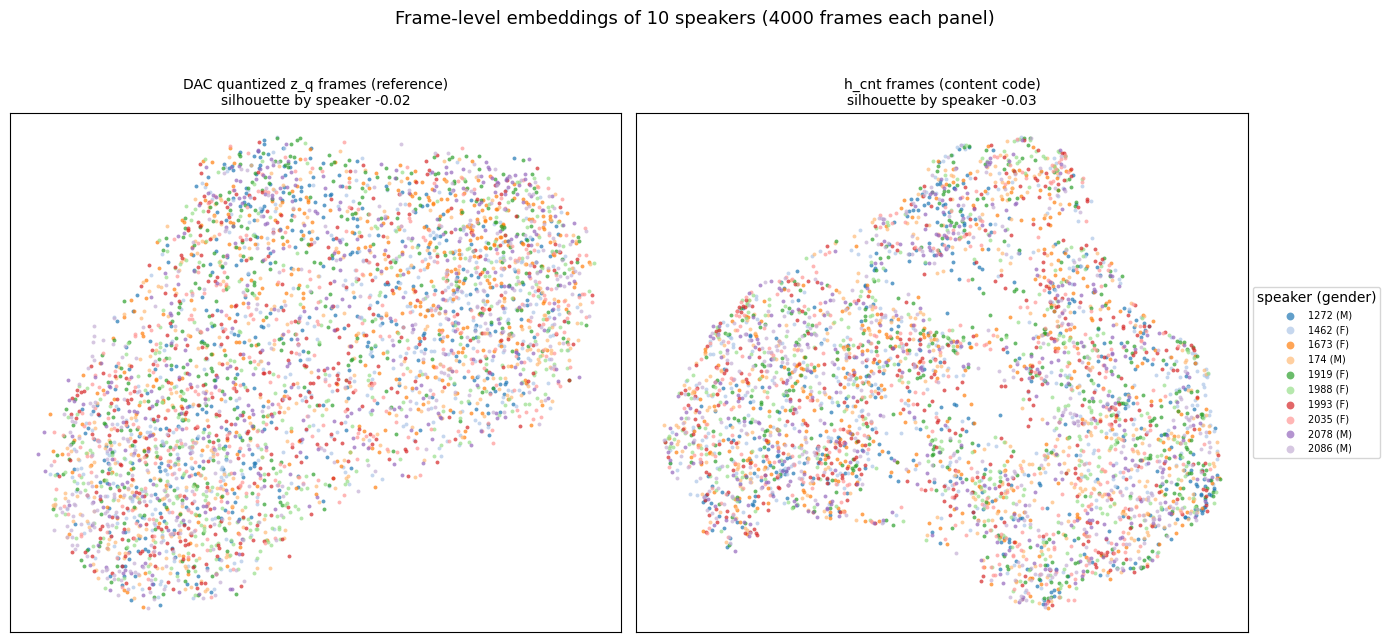

In [7]:
N_FRAME_SPEAKERS = 10
shown = np.arange(min(N_FRAME_SPEAKERS, len(speakers)))
mask = np.isin(frame_spk, shown)
frame_sets = [('DAC quantized z_q frames (reference)', frames['zq']), ('h_cnt frames (content code)', frames['h_cnt'])]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (name, X) in zip(axes, frame_sets):
    Xp = prepare(X[mask])
    E = embed_2d(Xp)
    sil = silhouette_score(Xp, frame_spk[mask], metric='cosine')
    for s in shown:
        sel = frame_spk[mask] == s
        ax.scatter(E[sel, 0], E[sel, 1], color=SPEAKER_COLORS[s], s=8, alpha=0.7, linewidths=0,
                   label='%s (%s)' % (speakers[s], utts.loc[utts['spk_idx'] == s, 'sex'].iloc[0]))
    ax.set_title('%s\nsilhouette by speaker %.2f' % (name, sil), fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(title='speaker (gender)', fontsize=7, markerscale=2, loc='center left', bbox_to_anchor=(1.0, 0.5))
fig.suptitle('Frame-level embeddings of %d speakers (%d frames each panel)' % (len(shown), mask.sum()), fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### The sparse codes themselves

`|h_cnt|` (top; rows = atoms, grouped by layer) and `h_spk` (bottom) for three utterances of different speakers.
Dotted lines separate the 4 residual layers. Different speakers should have clearly different `h_spk` bars, while `|h_cnt|` should differ because of what was said, not who said it.

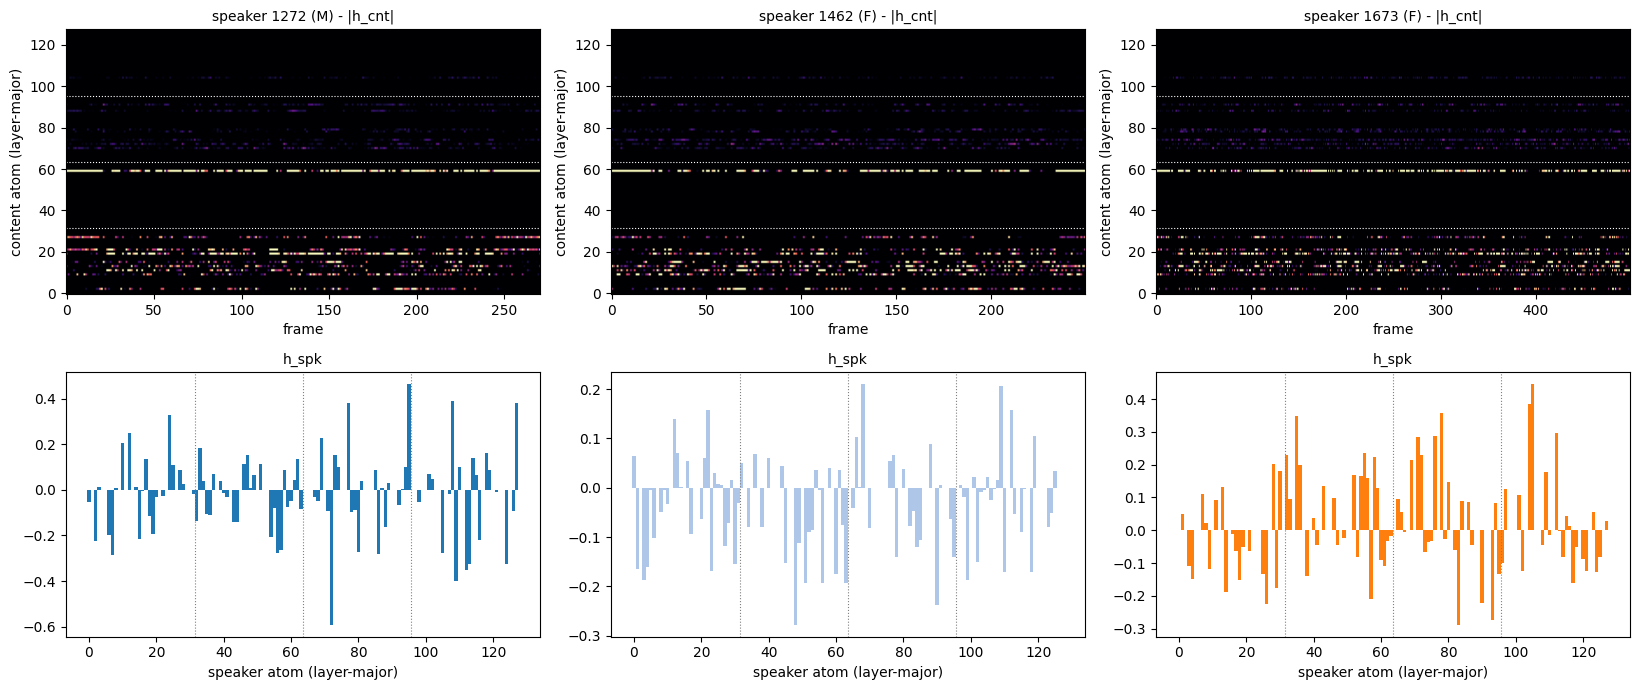

In [8]:
fig, axes = plt.subplots(2, len(examples), figsize=(5.5 * len(examples), 7), squeeze=False)
for col, (spk, ex) in enumerate(examples.items()):
    h_cnt, h_spk = ex['h_cnt'], ex['h_spk']
    ax = axes[0, col]
    im = ax.imshow(np.abs(h_cnt), aspect='auto', origin='lower', cmap='magma', vmax=np.percentile(np.abs(h_cnt), 99))
    for layer in range(1, N_LAYERS):
        ax.axhline(layer * K_CNT - 0.5, color='white', ls=':', lw=0.8)
    ax.set_title('speaker %s (%s) - |h_cnt|' % (spk, utts.loc[ex['utt'], 'sex']), fontsize=10)
    ax.set_xlabel('frame'); ax.set_ylabel('content atom (layer-major)')
    ax = axes[1, col]
    ax.bar(np.arange(len(h_spk)), h_spk, color=SPEAKER_COLORS[utts.loc[ex['utt'], 'spk_idx'] % 40], width=1.0)
    for layer in range(1, N_LAYERS):
        ax.axvline(layer * K_SPK - 0.5, color='gray', ls=':', lw=0.8)
    ax.set_title('h_spk', fontsize=10)
    ax.set_xlabel('speaker atom (layer-major)')
fig.tight_layout()
plt.show()

### Same-speaker vs different-speaker similarity (verification)

Cosine similarity between all pairs of utterances after z-scoring each feature, exactly the scoring used for the training metrics `EER` and `leak_EER`.
The more the two histograms overlap, the less speaker information the feature carries. **EER 50% = speaker cannot be verified at all.**

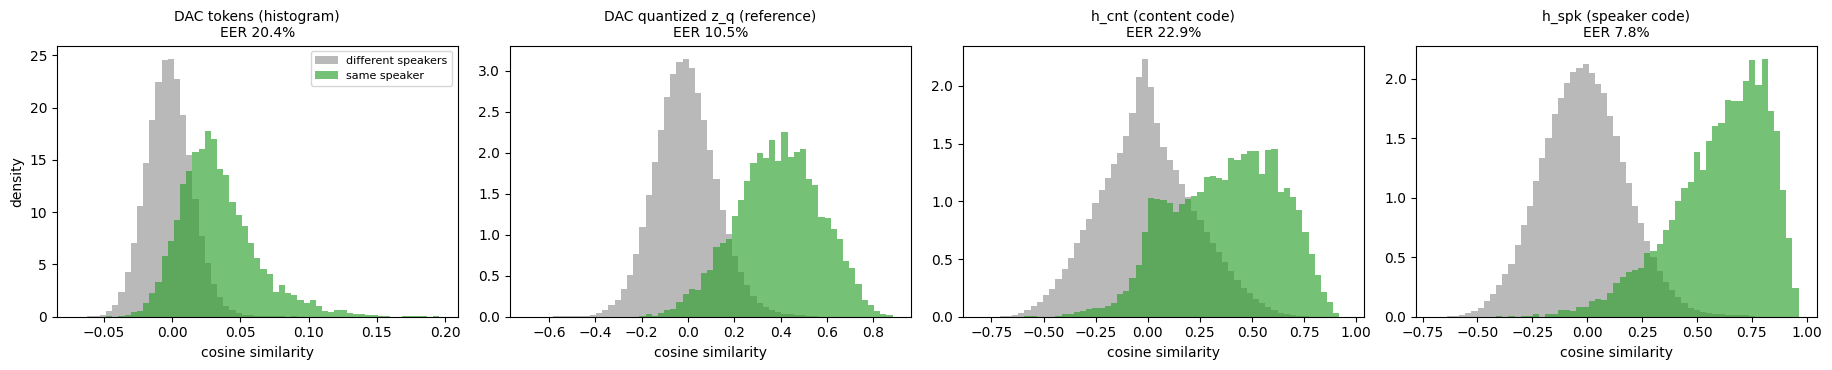

In [9]:
def eer_percent(scores, labels):
    fpr, tpr, _ = roc_curve(labels, scores)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    return 100 * (fpr[i] + fnr[i]) / 2


def pair_scores(X, spk):
    X = StandardScaler().fit_transform(X)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
    i, j = np.triu_indices(len(X), k=1)
    return np.sum(X[i] * X[j], axis=1), (spk[i] == spk[j]).astype(int)


verif_sets = [('DAC tokens (histogram)', 'dac_tokens', True)] + UTT_SETS
eer = {}
fig, axes = plt.subplots(1, len(verif_sets), figsize=(4.6 * len(verif_sets), 3.8))
for ax, (name, key, sqrt) in zip(axes, verif_sets):
    X = np.sqrt(feats[key]) if sqrt else feats[key]
    scores, same = pair_scores(X, spk_idx)
    eer[key] = eer_percent(scores, same)
    bins = np.linspace(scores.min(), scores.max(), 60)
    ax.hist(scores[same == 0], bins=bins, density=True, alpha=0.55, color='gray', label='different speakers')
    ax.hist(scores[same == 1], bins=bins, density=True, alpha=0.65, color='tab:green', label='same speaker')
    ax.set_title('%s\nEER %.1f%%' % (name, eer[key]), fontsize=10)
    ax.set_xlabel('cosine similarity')
axes[0].set_ylabel('density'); axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Probing classifiers

A classifier is trained to recover the speaker from each representation; the better it does, the more speaker information the representation contains.

* **Speaker ID** (closed set over the selected speakers, stratified `N_FOLDS`-fold CV across utterances), with a **linear** (logistic regression) and a **non-linear** (MLP) probe.
* **Gender**, cross-validated *across speakers* (the test speakers are never in the training folds), so it measures generalizing information.
* **Frame-level speaker ID** from single frames, cross-validated across utterances.
* A **label-shuffled control** (should sit at chance) shows the probes are not cheating.

Every representation goes through the same pipeline (standardize, PCA to at most 256 dimensions, classifier) so that the very different feature sizes stay comparable.
For DAC tokens the input is the token histogram over all codebooks (square-rooted).

In [10]:
chance_id = 1.0 / len(speakers)


def probe_pipeline(kind, sqrt=False, max_dims=256):
    steps = [FunctionTransformer(np.sqrt)] if sqrt else []
    steps += [StandardScaler(), PCA(n_components=max_dims, random_state=SEED)]
    steps.append(
        LogisticRegression(max_iter=1000, C=1.0) if kind == 'logreg'
        # fixed training budget: early stopping would hold out only ~10% of a small training set
        else MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-2, max_iter=500, random_state=SEED)
    )
    return make_pipeline(*steps)


def cv_scores(X, y, kind, sqrt=False, groups=None, stratified_groups=False, n_splits=N_FOLDS):
    """Mean and std of the CV accuracy; PCA is capped by the training-fold size."""
    n_train = int(len(X) * (1 - 1.0 / n_splits)) - 1
    max_dims = min(256, X.shape[1], n_train)
    if stratified_groups:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    elif groups is not None:
        cv = GroupKFold(n_splits=n_splits)
    else:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    scores = cross_val_score(probe_pipeline(kind, sqrt, max_dims), X, y, cv=cv, groups=groups, scoring='accuracy', n_jobs=n_splits)
    return scores.mean(), scores.std()


gender = (utts['sex'].values == 'F').astype(int)
PROBE_SETS = [  # (name, feature key, sqrt-transform)
    ('DAC tokens (histogram)', 'dac_tokens', True),
    ('DAC quantized z_q', 'dac_zq', False),
    ('h_cnt (content code)', 'h_cnt', False),
    ('h_spk (speaker code)', 'h_spk', False),
]

rows = []
for name, key, sqrt in tqdm(PROBE_SETS, desc='utterance-level probes'):
    X = feats[key]
    id_lr = cv_scores(X, spk_idx, 'logreg', sqrt)
    id_mlp = cv_scores(X, spk_idx, 'mlp', sqrt)
    gen = cv_scores(X, gender, 'logreg', sqrt, groups=spk_idx, stratified_groups=True)
    rows.append(dict(representation=name, key=key, id_logreg=id_lr[0], id_logreg_std=id_lr[1],
                     id_mlp=id_mlp[0], id_mlp_std=id_mlp[1], gender=gen[0], gender_std=gen[1], eer=eer[key]))

shuffled = rng.permutation(spk_idx)
control = cv_scores(feats['h_cnt'], shuffled, 'logreg')
print('control: h_cnt with shuffled speaker labels -> %.3f (chance %.3f)' % (control[0], chance_id))

results = pd.DataFrame(rows).set_index('representation')
display_cols = results[['id_logreg', 'id_mlp', 'gender', 'eer']].copy()
display_cols.columns = ['speaker ID (linear)', 'speaker ID (MLP)', 'gender (unseen speakers)', 'verification EER %']
print('chance: speaker ID %.3f | gender ~0.5 | EER 50%%' % chance_id)
display_cols.round(3)

utterance-level probes:   0%|          | 0/4 [00:00<?, ?it/s]

control: h_cnt with shuffled speaker labels -> 0.030 (chance 0.025)
chance: speaker ID 0.025 | gender ~0.5 | EER 50%


,speaker ID (linear),speaker ID (MLP),gender (unseen speakers),verification EER %
representation,,,,
DAC tokens (histogram),0.918,0.648,0.776,20.404
DAC quantized z_q,0.994,0.959,0.819,10.459
h_cnt (content code),0.838,0.855,0.859,22.852
h_spk (speaker code),0.992,0.989,0.814,7.781


### Frame-level probe

Speaker ID from a **single frame** (`FRAMES_PER_UTT` random frames per utterance; folds are split by utterance, so frames of a test utterance are never seen in training).
`h_spk` is constant per utterance and is therefore not part of this probe.

In [11]:
frame_results = {}
for name, key in [('DAC quantized z_q', 'zq'), ('h_cnt (content code)', 'h_cnt')]:
    frame_results[name] = cv_scores(frames[key], frame_spk, 'logreg', groups=frames['utt'], n_splits=4)
    print('%-26s frame-level speaker ID: %.3f +- %.3f (chance %.3f)' % (name, *frame_results[name], chance_id))

DAC quantized z_q          frame-level speaker ID: 0.157 +- 0.005 (chance 0.025)
h_cnt (content code)       frame-level speaker ID: 0.040 +- 0.002 (chance 0.025)


### Where does the leakage live? Per-layer content codes

The disentangler is a stack of 4 residual layers, and later layers code what earlier ones left over. Speaker ID from each layer's `h_cnt` alone
shows which layers still carry speaker information.

In [12]:
K_TOTAL = N_LAYERS * K_CNT


def layer_columns(layer):
    """Columns of the pooled h_cnt feature (mean | std | mean-abs blocks) that belong to one layer."""
    return np.concatenate([np.arange(block * K_TOTAL + layer * K_CNT, block * K_TOTAL + (layer + 1) * K_CNT) for block in range(3)])


layer_rows = []
for layer in range(N_LAYERS):
    acc, std = cv_scores(feats['h_cnt'][:, layer_columns(layer)], spk_idx, 'logreg')
    layer_rows.append(dict(layer=layer, id_logreg=acc, id_logreg_std=std))
    print('h_cnt layer %d only: speaker ID %.3f +- %.3f' % (layer, acc, std))
layer_results = pd.DataFrame(layer_rows)

h_cnt layer 0 only: speaker ID 0.746 +- 0.031
h_cnt layer 1 only: speaker ID 0.175 +- 0.031
h_cnt layer 2 only: speaker ID 0.544 +- 0.043
h_cnt layer 3 only: speaker ID 0.075 +- 0.016


## 6. How much speaker information was removed?

The reference is the codec representation the model started from (DAC tokens / `z_q`).
`removed = (reference - h_cnt) / (reference - chance)`: 0% means `h_cnt` carries as much speaker information as the codec, 100% means it is at chance.
A representation's speaker information is judged by the **strongest probe** applied to it (the "best probe" row), because a weak probe on one feature type (for example an MLP on a sparse token histogram) can understate what is there.
For the verification EER the same formula is applied with chance = 50%. A **negative** value means `h_cnt` carries *more* speaker information than the reference.
The single-frame probe has no DAC-token row: its DAC entry uses the dequantized `z_q` of a frame.

In [ ]:
ref_tokens, ref_zq, cnt, spk = (results.loc[n] for n in ['DAC tokens (histogram)', 'DAC quantized z_q', 'h_cnt (content code)', 'h_spk (speaker code)'])


def removed(reference, value, chance):
    return 100.0 * (reference - value) / (reference - chance)


summary = pd.DataFrame({
    'DAC tokens': [ref_tokens.id_logreg, ref_tokens.id_mlp, max(ref_tokens.id_logreg, ref_tokens.id_mlp), ref_tokens.eer, ref_tokens.gender],
    'DAC z_q': [ref_zq.id_logreg, ref_zq.id_mlp, max(ref_zq.id_logreg, ref_zq.id_mlp), ref_zq.eer, ref_zq.gender],
    'h_cnt': [cnt.id_logreg, cnt.id_mlp, max(cnt.id_logreg, cnt.id_mlp), cnt.eer, cnt.gender],
    'h_spk': [spk.id_logreg, spk.id_mlp, max(spk.id_logreg, spk.id_mlp), spk.eer, spk.gender],
    'chance': [chance_id, chance_id, chance_id, 50.0, 0.5],
}, index=['speaker ID (linear)', 'speaker ID (MLP)', 'speaker ID (best probe)', 'verification EER %', 'gender']).astype(float)
summary['removed vs DAC tokens %'] = [removed(summary.loc[m, 'DAC tokens'], summary.loc[m, 'h_cnt'], summary.loc[m, 'chance']) for m in summary.index]
summary['removed vs DAC z_q %'] = [removed(summary.loc[m, 'DAC z_q'], summary.loc[m, 'h_cnt'], summary.loc[m, 'chance']) for m in summary.index]
print(summary.round(3).to_string())
print()
print('Headline (best speaker-ID probe): h_cnt reaches %.0f%% accuracy vs %.0f%% for DAC z_q and %.0f%% for the token histogram (chance %.1f%%).' % (
    100 * summary.loc['speaker ID (best probe)', 'h_cnt'], 100 * summary.loc['speaker ID (best probe)', 'DAC z_q'],
    100 * summary.loc['speaker ID (best probe)', 'DAC tokens'], 100 * chance_id))
print('Speaker information removed relative to DAC z_q: %.0f%% (speaker ID, best probe), %.0f%% (verification EER).' % (
    summary.loc['speaker ID (best probe)', 'removed vs DAC z_q %'], summary.loc['verification EER %', 'removed vs DAC z_q %']))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))
names = list(results.index)
x = np.arange(len(names))
width = 0.27
ax1.bar(x - width, results['id_logreg'], width, yerr=results['id_logreg_std'], label='linear probe', color='tab:blue')
ax1.bar(x, results['id_mlp'], width, yerr=results['id_mlp_std'], label='MLP probe', color='tab:orange')
frame_acc = [frame_results.get(n, (np.nan, 0))[0] for n in names]
ax1.bar(x + width, frame_acc, width, label='single-frame probe', color='tab:green')
ax1.axhline(chance_id, color='gray', ls='--', label='chance')
ax1.set_ylim(0, 1.3)
ax1.set_title('Speaker ID accuracy (higher = more speaker information)')
ax1.set_xticks(x); ax1.set_xticklabels([n.replace(' (', '\n(') for n in names], fontsize=8)
ax1.legend(fontsize=8, ncol=4, loc='upper center')

ax2.bar(x, results['eer'], color=['tab:purple' if k == 'h_cnt' else 'silver' for k in results['key']])
ax2.axhline(50, color='gray', ls='--', label='chance (50%)')
ax2.set_ylim(0, 55)
ax2.set_title('Verification EER (lower = more speaker information)')
ax2.set_xticks(x); ax2.set_xticklabels([n.replace(' (', '\n(') for n in names], fontsize=8)
ax2.legend(fontsize=8)

ax3.bar(layer_results['layer'], layer_results['id_logreg'], yerr=layer_results['id_logreg_std'], color='tab:purple', label='h_cnt, one layer')
ax3.axhline(cnt.id_logreg, color='black', ls='-', lw=1, label='h_cnt, all layers')
ax3.axhline(chance_id, color='gray', ls='--', label='chance')
ax3.set_ylim(0, 1.0)
ax3.set_xticks(layer_results['layer'])
ax3.set_xlabel('sparse layer'); ax3.set_title('Speaker ID from each layer\'s content code')
ax3.legend(fontsize=8)
fig.suptitle('Speaker information in DAC tokens vs h_cnt vs h_spk - %s' % MODEL_DIR.name, fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## How to read the results

* **`h_spk` high, `h_cnt` low** (near the dashed chance lines) is the goal. The "removed %" rows quantify it relative to the codec features.
* **`h_cnt` still far above chance** means speaker information leaks into the content branch. A non-linear or single-frame probe that beats the linear utterance-level probe means the leak is
  not visible to the linear/pooled statistics the training penalties and `leak_EER` look at.
* The per-layer plot shows whether leakage sits in the first layers or in the later residual layers.
* Close to the shuffled-label control (about chance) means the probe pipeline is sound; if the control is clearly above chance something is wrong with the folds.
* Speaker ID uses 20 utterances per speaker, many from the same chapter (same recording session), which makes it easier than speaker ID across sessions. Use the *relative* numbers (DAC vs `h_cnt`), not the absolute accuracy.
* Raise `N_SPEAKERS` / `UTTS_PER_SPEAKER` for tighter estimates (the plotted error bars are the standard deviation over folds).